In [22]:
from torchvision import datasets, models
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [23]:
import kagglehub
path = kagglehub.dataset_download("tongpython/cat-and-dog")
print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/tongpython/cat-and-dog


In [24]:
import torchvision.transforms as transforms
from torch.utils.data import random_split

size = 256
train_transform = transforms.Compose([
    transforms.Resize((size, size)),        # resize to model input size
    transforms.RandomHorizontalFlip(),    # horizontal flip augmentation
    #transforms.RandomRotation(15),        # rotate ±15 degrees
    #transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),                # convert PIL → float tensor [0.0,1.0]
    transforms.Normalize(mean=[0.485,0.456, 0.406],std=[0.229, 0.224,  0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456, 0.406],std=[0.229, 0.224,  0.225])
])

train_folder = path+'/training_set/training_set'
test_folder = path+'/test_set/test_set'

train_data = datasets.ImageFolder(train_folder, transform = train_transform)
val_test_data = datasets.ImageFolder(test_folder,transform = val_transform)

# Split original test dataset into validation (50%) and test (50%)
val_size = len(val_test_data) // 2
test_size = len(val_test_data) - val_size

val_data, test_data = random_split(
    val_test_data,
    [val_size, test_size]
)

In [25]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classess and Indices: ' , train_data.class_to_idx)

Dataset Summary
Train Data:  8005
Validation Data:  1011
Test Data:  1012
Classess and Indices:  {'cats': 0, 'dogs': 1}


In [26]:
batch_size = 32
learning_rate=1e-3
epoch_number = 3

In [27]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [45]:
vgg_model = models.vgg16(weights=models.VGG16_Weights.DEFAULT).to(device)
print(vgg_model)

VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1

In [47]:
summary(vgg_model.features, input_size=(3,size,size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]           1,792
              ReLU-2         [-1, 64, 256, 256]               0
            Conv2d-3         [-1, 64, 256, 256]          36,928
              ReLU-4         [-1, 64, 256, 256]               0
         MaxPool2d-5         [-1, 64, 128, 128]               0
            Conv2d-6        [-1, 128, 128, 128]          73,856
              ReLU-7        [-1, 128, 128, 128]               0
            Conv2d-8        [-1, 128, 128, 128]         147,584
              ReLU-9        [-1, 128, 128, 128]               0
        MaxPool2d-10          [-1, 128, 64, 64]               0
           Conv2d-11          [-1, 256, 64, 64]         295,168
             ReLU-12          [-1, 256, 64, 64]               0
           Conv2d-13          [-1, 256, 64, 64]         590,080
             ReLU-14          [-1, 256,

In [29]:
conv_layers_count = 0
for layer in vgg_model.features:
    if isinstance(layer, torch.nn.Conv2d):
        conv_layers_count += 1
print(f"Number of convolutional layers in model.features: {conv_layers_count}")

liner_layers_count = 0
for layer in vgg_model.classifier:
    if isinstance(layer, nn.Linear):
        liner_layers_count += 1
print(f"Number of Fully Connected Liner layers Classifier: {liner_layers_count}")

print(f"Total layers (Feature Extrection + Classifier): {conv_layers_count+liner_layers_count}")

Number of convolutional layers in model.features: 13
Number of Fully Connected Liner layers Classifier: 3
Total layers (Feature Extrection + Classifier): 16


In [57]:
from torch.optim import SGD, Adam

class CNNModel(nn.Module):
    def __init__(self):
        super(CNNModel, self).__init__()
        # Feature extraction layers
        self.features = vgg_model.features

        for param in self.features.parameters():
          param.requires_grad = True

        # Classification layers
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(128, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [59]:
def get_model():
    model = CNNModel().to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [32]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [60]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,size,size));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 256, 256]           1,792
              ReLU-2         [-1, 64, 256, 256]               0
            Conv2d-3         [-1, 64, 256, 256]          36,928
              ReLU-4         [-1, 64, 256, 256]               0
         MaxPool2d-5         [-1, 64, 128, 128]               0
            Conv2d-6        [-1, 128, 128, 128]          73,856
              ReLU-7        [-1, 128, 128, 128]               0
            Conv2d-8        [-1, 128, 128, 128]         147,584
              ReLU-9        [-1, 128, 128, 128]               0
        MaxPool2d-10          [-1, 128, 64, 64]               0
           Conv2d-11          [-1, 256, 64, 64]         295,168
             ReLU-12          [-1, 256, 64, 64]               0
           Conv2d-13          [-1, 256, 64, 64]         590,080
             ReLU-14          [-1, 256,

In [34]:
## Training Loop ###
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/3] | Train Loss: 0.0838 | Train Accuracy: 97.04% | Val Loss: 0.0329 | Val Accuracy: 99.21%
Epoch [2/3] | Train Loss: 0.0498 | Train Accuracy: 98.26% | Val Loss: 0.0274 | Val Accuracy: 99.11%
Epoch [3/3] | Train Loss: 0.0439 | Train Accuracy: 98.33% | Val Loss: 0.0305 | Val Accuracy: 98.91%


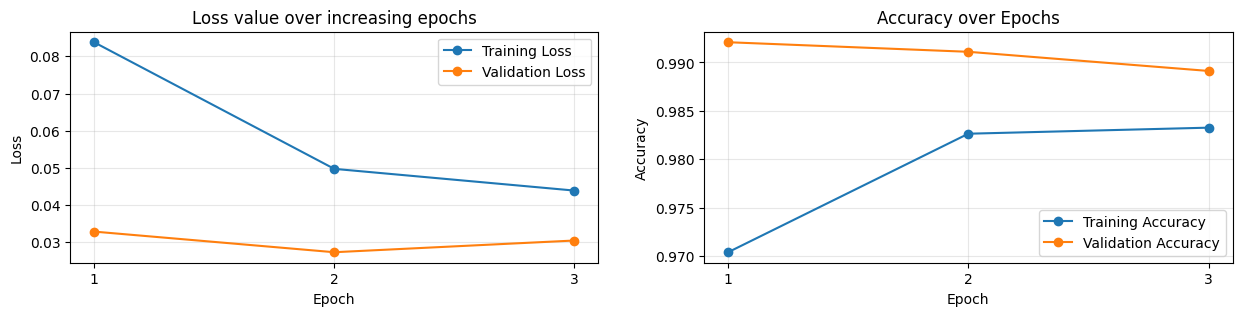

In [35]:
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0836544..2.622571].


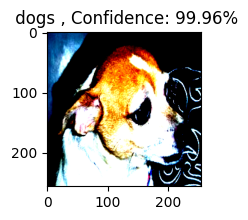

In [36]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {train_data.classes[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

In [37]:
test_loss, test_acc =  validation(test_dl,model,loss_fn)
print(f'Test Loss : {test_loss:0.2f} , Test Accuracy: {test_acc*100:0.2f}%')

Test Loss : 0.04 , Test Accuracy: 98.81%


In [38]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

class_names = val_test_data.classes  # from ImageFolder

model.eval()
misclassified = []
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_dl:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        # Save all predictions and labels for confusion matrix
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        # Store misclassified images
        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append((img.cpu(), true.cpu(), pred.cpu()))

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.3815396..2.465708].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.5870366..2.2489083].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].


Total misclassified samples: 11


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0357141..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0151556..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.343704].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9466565..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.5702832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.64].
Clipping input

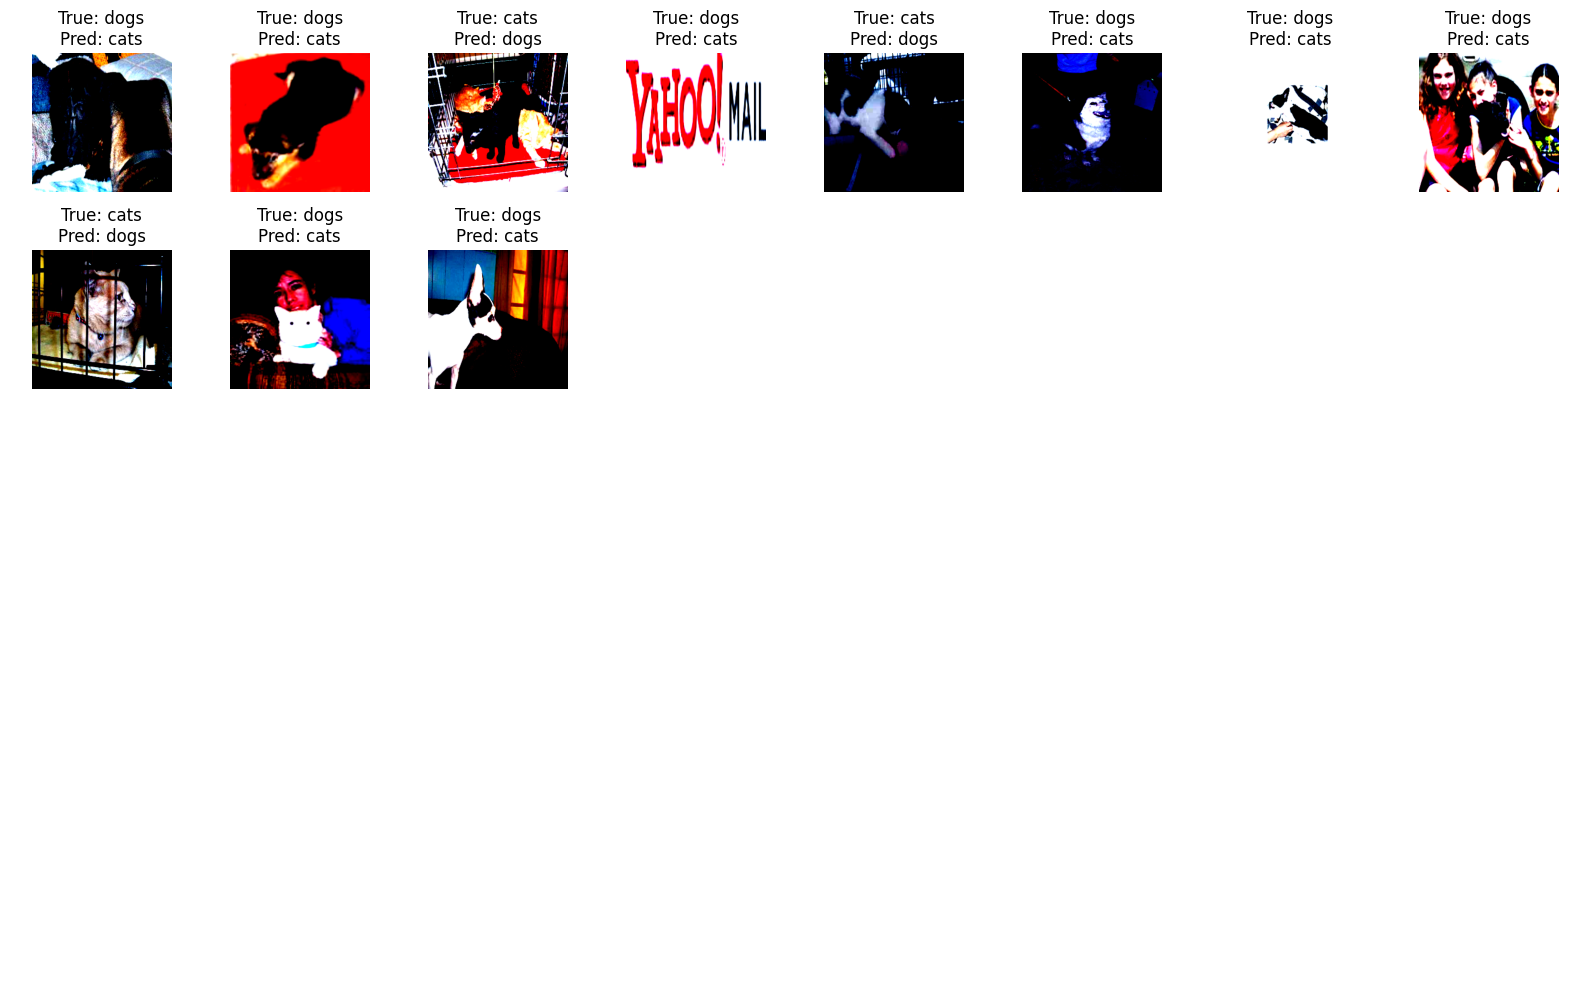

In [39]:
print(f"Total misclassified samples: {len(misclassified)}")
num_rows = 5
num_cols = 8
num_to_show = num_rows * num_cols
num_to_show = min(num_to_show, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2, num_rows*2))
axes = axes.flatten()  # flatten for easy iteration

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    img = img.permute(1, 2, 0)  # CxHxW -> HxWxC
    axes[idx].imshow(img)
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}")
    axes[idx].axis('off')

# Turn off any unused subplots
for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

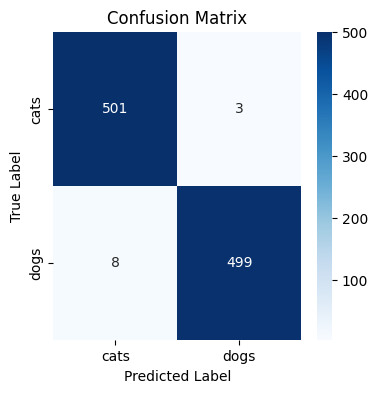

In [40]:
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(4, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=train_data.classes, yticklabels=train_data.classes)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [48]:
model

CNNModel(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0, dilat

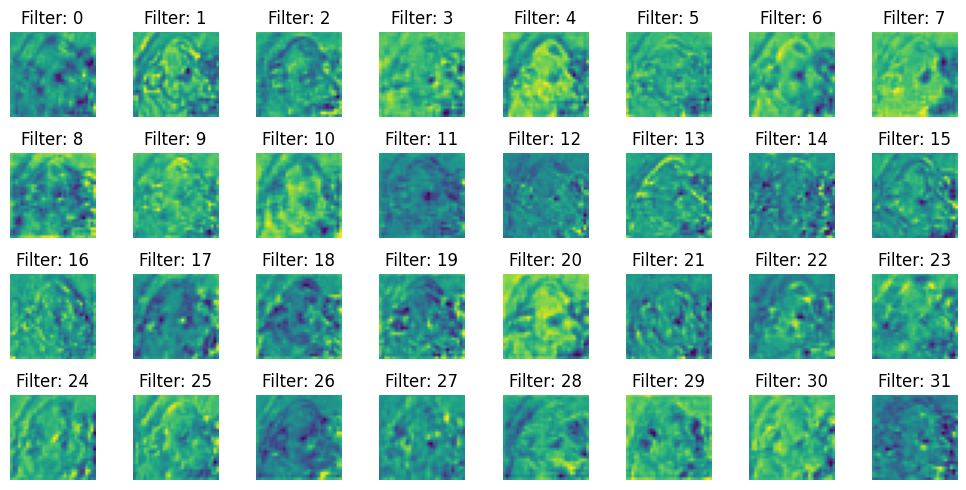

In [51]:
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

fv_model = nn.Sequential(*model.features[:18])
intermediate_output = fv_model(img)

fig, ax = plt.subplots(4, 8, figsize=(10, 5))
for ix, axis in enumerate(ax.flat):
    axis.set_title('Filter: ' + str(ix))
    axis.imshow(intermediate_output[0, ix].cpu().detach().numpy(), cmap='viridis')
    axis.axis('off')
plt.tight_layout()
plt.show()

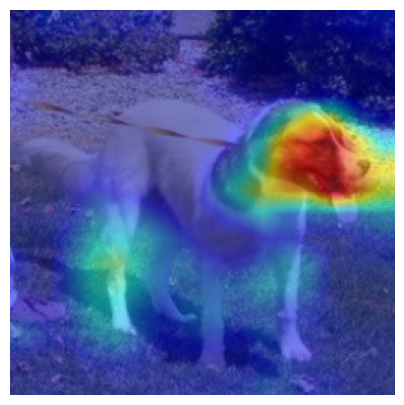

In [54]:
!pip install -qq grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
import matplotlib.pyplot as plt

test_img, label = test_data[612]
rgb_img = test_img.view(-1,3,size,size).to(device)

for params in model.features.parameters():
  params.requires_grad = True

# Last conv layer in your CNN
target_layers = [model.features[29]]

# Create GradCAM object
cam = GradCAM(model=model, target_layers=target_layers)

# Generate CAM
grayscale_cam = cam(input_tensor=rgb_img, targets=None)  # None = highest scoring class
grayscale_cam = grayscale_cam[0, :]  # batch size = 1

# Convert tensor to HWC format for overlay
rgb_img_np = rgb_img[0].permute(1,2,0).cpu().numpy()
rgb_img_np = (rgb_img_np - rgb_img_np.min()) / (rgb_img_np.max() - rgb_img_np.min())  # normalize 0-1

# Overlay Grad-CAM
visualization = show_cam_on_image(rgb_img_np, grayscale_cam, use_rgb=True)


for params in model.features.parameters():
  params.requires_grad = False


plt.figure(figsize=(5,5))
plt.imshow(visualization)
plt.axis('off')
plt.savefig("GRAD_CAM.pdf", bbox_inches="tight", dpi=150)
plt.show()